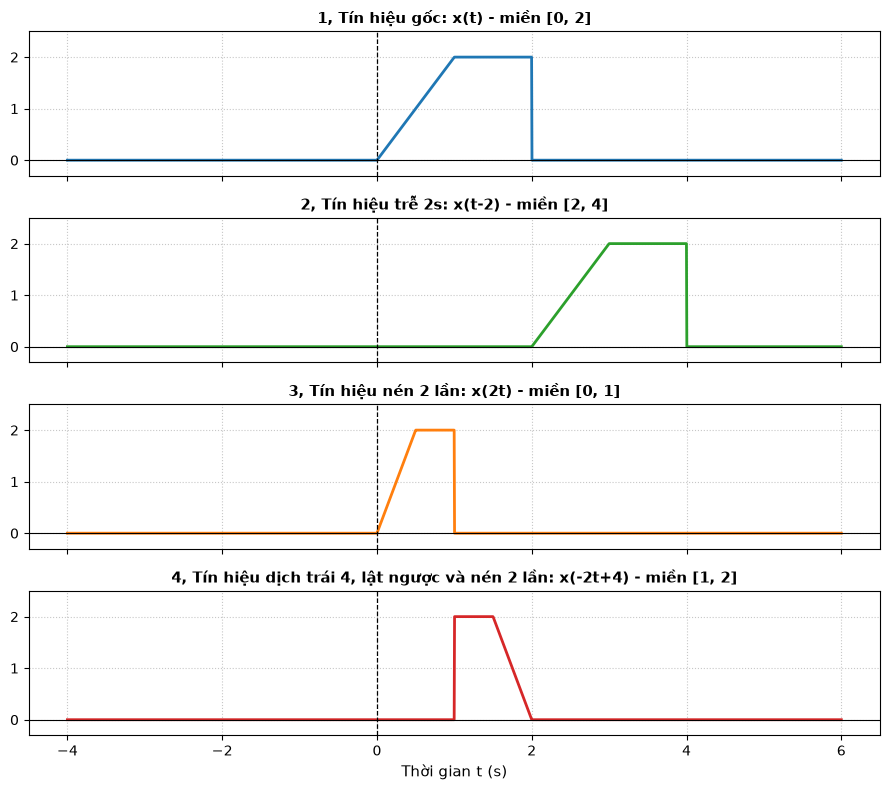

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# --- Phần 1: Định nghĩa các tín hiệu cơ bản ---

def u(t):
    """Hàm bước nhảy đơn vị u(t)"""
    return np.where(t >= 0, 1.0, 0.0)

def x(t):
    """
    Tín hiệu gốc x(t) xây dựng từ hàm bước nhảy u(t):
    - Từ t = 0 đến 1: đường dốc tăng từ 0 lên 2 -> 2*t * [u(t) - u(t-1)]
    - Từ t = 1 đến 2: mức hằng biên độ 2        -> 2 * [u(t-1) - u(t-2)]
    """

    doan_doc = 2 * t * (u(t) - u(t-1))
    doan_bang = 2.0 * (u(t-1) - u(t-2))
    return doan_doc + doan_bang

# --- Phần 2: Tạo trục thời gian & biến đổi ---
t = np.linspace(-4, 6, 2000)

y0 = x(t)            # Gốc: tồn tại trên [0, 2]
y1 = x(t - 2)        # Trễ 2s (dịch phải): tồn tại trên [2, 4]
y2 = x(2 * t)        # Nén 2 lần: tồn tại trên [0, 1]
y3 = x(-2 * t + 4)   # Dịch trái 4, lật ngược và nén 2 lần: tồn tại trên [1, 2]

# --- Phần 3: Trực quan hóa bằng matplotlib --- 
fig, axs = plt.subplots(4, 1, figsize=(9, 8), sharex=True)

danh_sach_ve = [
    (y0, "1, Tín hiệu gốc: x(t) - miền [0, 2]", "tab:blue"),
    (y1, "2, Tín hiệu trễ 2s: x(t-2) - miền [2, 4]", "tab:green"),
    (y2, "3, Tín hiệu nén 2 lần: x(2t) - miền [0, 1]", "tab:orange"),
    (y3, "4, Tín hiệu dịch trái 4, lật ngược và nén 2 lần: x(-2t+4) - miền [1, 2]", "tab:red")
]

for ax, (tin_hieu, tieu_de, mau) in zip(axs, danh_sach_ve):
    ax.plot(t, tin_hieu, color=mau, linewidth=2)
    ax.axvline(0, color='black', linestyle='--', linewidth=0.9) # Trục tung t = 0
    ax.axhline(0, color='black', linewidth=0.8)                 # Trục hoành
    ax.set_title(tieu_de, fontsize=11, fontweight='bold')
    ax.set_ylim(-0.3, 2.5)
    ax.grid(True, linestyle=':', alpha=0.7)

axs[-1].set_xlabel("Thời gian t (s)", fontsize=11)
plt.tight_layout()
plt.show()


Sai số tái tạo lớn nhất: 0.00e+00


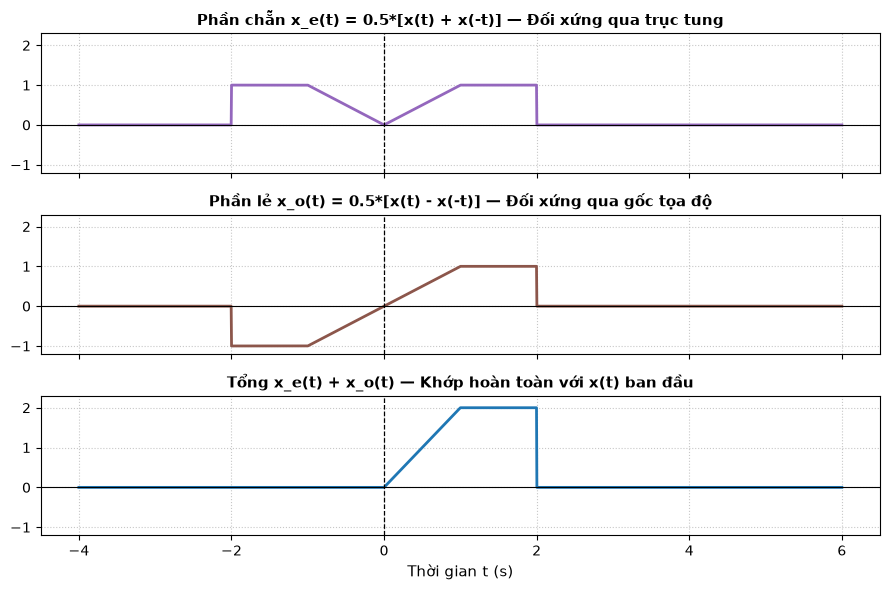

In [2]:
# --- Phân tích tín hiệu thành phần chẵn và lẻ ---

xe = 0.5 * (x(t) + x(-t)) # Phần chẵn: x_e(t)
xo = 0.5 * (x(t) - x(-t)) # Phần lẻ: x_o(t)
x_reconstructed = xe + xo # Tái tạo lại tín hiệu gốc

# Kiểm tra sai số bằng số giữa tín hiệu tạo và tín hiệu gốc
sai_so = np.max(np.abs(x_reconstructed - x(t)))
print(f"Sai số tái tạo lớn nhất: {sai_so:.2e}")

# Vẽ đồ thị đối chiếu
fig, axs = plt.subplots(3, 1, figsize=(9, 6), sharex=True)

do_thi_chan_le = [
    (xe, "Phần chẵn x_e(t) = 0.5*[x(t) + x(-t)] — Đối xứng qua trục tung", "tab:purple"),
    (xo, "Phần lẻ x_o(t) = 0.5*[x(t) - x(-t)] — Đối xứng qua gốc tọa độ", "tab:brown"),
    (x_reconstructed, "Tổng x_e(t) + x_o(t) — Khớp hoàn toàn với x(t) ban đầu", "tab:blue")
]

for ax, (sig, title, color) in zip(axs, do_thi_chan_le):
    ax.plot(t, sig, color=color, linewidth=2)
    ax.axvline(0, color='black', linestyle='--', linewidth=0.9) # Trục tung t = 0
    ax.axhline(0, color='black', linewidth=0.8)                 # Trục hoành
    ax.set_title(title, fontsize=10.5, fontweight='bold')
    ax.set_ylim(-1.2, 2.3)
    ax.grid(True, linestyle=':', alpha=0.7)

axs[-1].set_xlabel("Thời gian t (s)", fontsize=11)
plt.tight_layout()
plt.show()